# 02 · Análise exploratória com foco em negócio

**Pergunta orientadora:** *quais fatores da operação realmente fazem um cliente virar promotor ou detrator, e em que momento a experiência "quebra"?*

As respostas estão escritas para quem **não é da área de estatística**. Cada gráfico vem com uma leitura em linguagem de gestão. Todos os gráficos ficam salvos em `reports/figures/` e são reutilizados na apresentação.

**Perguntas do enunciado respondidas aqui:**
1. Quais fatores parecem mais críticos para a satisfação? (seções 3 a 5 e 8)
2. O que mais gera detratores? (seção 8)
3. Existe um "ponto de ruptura" na experiência? (seções 3 e 6)
4. Que tipo de cliente tende a ter NPS mais alto ou mais baixo? (seção 7)

Ao final, a seção 9 estima o ganho potencial de atacar o atraso, e a seção 10 resume as conclusões.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
from src.nps_utils import (
    COR_DESTAQUE, COR_NEUTRA, COR_TEXTO, COR_TEXTO_SECUNDARIO, CORES_CATEGORIA, ORDEM_CATEGORIAS,
    aplicar_estilo_graficos, calcular_nps, carregar_base_tratada, resumo_nps_por, salvar_figura,
)

aplicar_estilo_graficos()
pd.set_option("display.float_format", "{:.1f}".format)

df = carregar_base_tratada()
print(f"Pedidos analisados: {len(df):,}")

Pedidos analisados: 2,500

In [2]:
def barras_100_por_categoria(ax, resumo_categorias: pd.DataFrame, titulo: str, rotulo_x: str = ""):
    """Barras empilhadas 100% (detrator / neutro / promotor) com o NPS escrito acima de cada barra."""
    base = np.zeros(len(resumo_categorias))
    posicoes = np.arange(len(resumo_categorias))
    for categoria in ORDEM_CATEGORIAS:
        valores = resumo_categorias[categoria].values
        ax.bar(posicoes, valores, bottom=base, color=CORES_CATEGORIA[categoria],
               width=0.68, edgecolor="white", linewidth=1.5, label=categoria)
        base += valores
    nps_grupo = resumo_categorias["Promotor"] - resumo_categorias["Detrator"]
    for x, valor in zip(posicoes, nps_grupo):
        ax.text(x, 103, f"NPS\n{valor:+.0f}", ha="center", va="bottom", fontsize=10,
                fontweight="bold", color=COR_TEXTO)
    ax.set_xticks(posicoes, resumo_categorias.index)
    ax.set_ylim(0, 125)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_title(titulo, pad=12)
    ax.set_xlabel(rotulo_x)


def composicao_por(coluna: str) -> pd.DataFrame:
    """Percentual de detratores, neutros e promotores dentro de cada grupo."""
    return (pd.crosstab(df[coluna], df["nps_categoria"], normalize="index")
              .reindex(columns=ORDEM_CATEGORIAS, fill_value=0) * 100)

## 1. Como está a satisfação hoje?

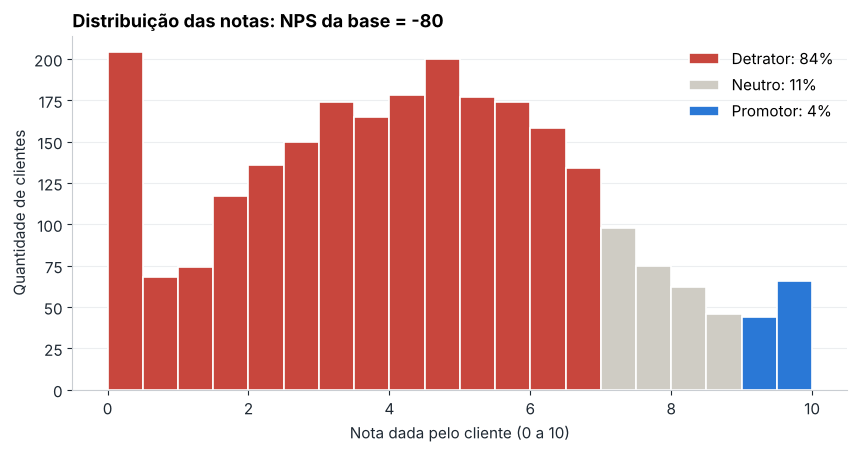

,% dos clientes
nps_categoria,
Detrator,84.4
Neutro,11.2
Promotor,4.4


In [3]:
nps_geral = calcular_nps(df["nps_categoria"])
composicao = df["nps_categoria"].value_counts(normalize=True).reindex(ORDEM_CATEGORIAS) * 100

fig, ax = plt.subplots(figsize=(10, 4.6))
limites = np.arange(0, 10.5, 0.5)
for categoria, (inicio, fim) in {"Detrator": (0, 7), "Neutro": (7, 9), "Promotor": (9, 10.01)}.items():
    notas = df.loc[df["nps_categoria"] == categoria, "nps_score"]
    ax.hist(notas, bins=limites[(limites >= inicio) & (limites <= fim + 0.5)], color=CORES_CATEGORIA[categoria],
            edgecolor="white", linewidth=1.2, label=f"{categoria}: {composicao[categoria]:.0f}%")
ax.set_title(f"Distribuição das notas: NPS da base = {nps_geral:+.0f}")
ax.set_xlabel("Nota dada pelo cliente (0 a 10)")
ax.set_ylabel("Quantidade de clientes")
ax.legend(frameon=False, loc="upper right")
salvar_figura(fig, "fig01_distribuicao_notas.png")
plt.show()

composicao.round(1).to_frame("% dos clientes")

**Leitura para gestão:** de cada 100 clientes, **84 são detratores**, 11 são neutros e só **4 são promotores**. O NPS da base é **−80**. A nota mais comum fica entre 3 e 6, e a empresa tem muito mais clientes propensos a falar mal do que a recomendar.

## 2. Por que isso importa: satisfação e recompra

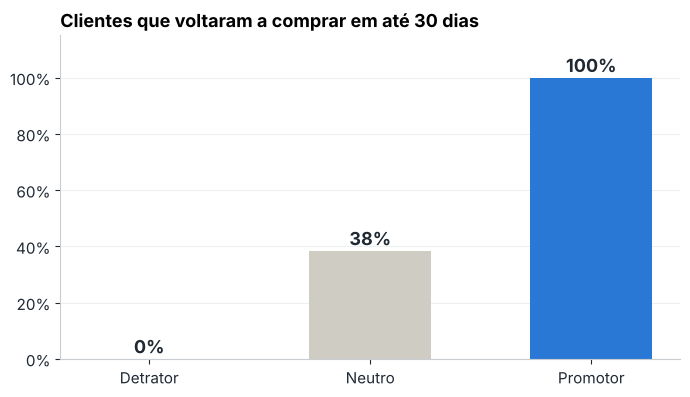

In [4]:
recompra = df.groupby("nps_categoria", observed=True)["repeat_purchase_30d"].mean().mul(100).reindex(ORDEM_CATEGORIAS)

fig, ax = plt.subplots(figsize=(8, 4.2))
barras = ax.bar(recompra.index, recompra.values, color=[CORES_CATEGORIA[c] for c in recompra.index], width=0.55)
for barra, valor in zip(barras, recompra.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 2, f"{valor:.0f}%", ha="center",
            fontsize=13, fontweight="bold", color=COR_TEXTO)
ax.set_ylim(0, 115)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Clientes que voltaram a comprar em até 30 dias")
salvar_figura(fig, "fig02_recompra_por_categoria.png")
plt.show()

**Leitura para gestão:** **todos** os promotores voltaram a comprar em até 30 dias, contra **nenhum** detrator. Satisfação vira receita recorrente.

> ⚠️ Uma relação tão perfeita (100% × 0%) é rara na vida real e indica que a base pode ter sido simulada. A direção do efeito é coerente com o mercado, mas o tamanho dele deve ser lido com cautela.

## 3. O fator nº 1: atraso na entrega e o ponto de ruptura

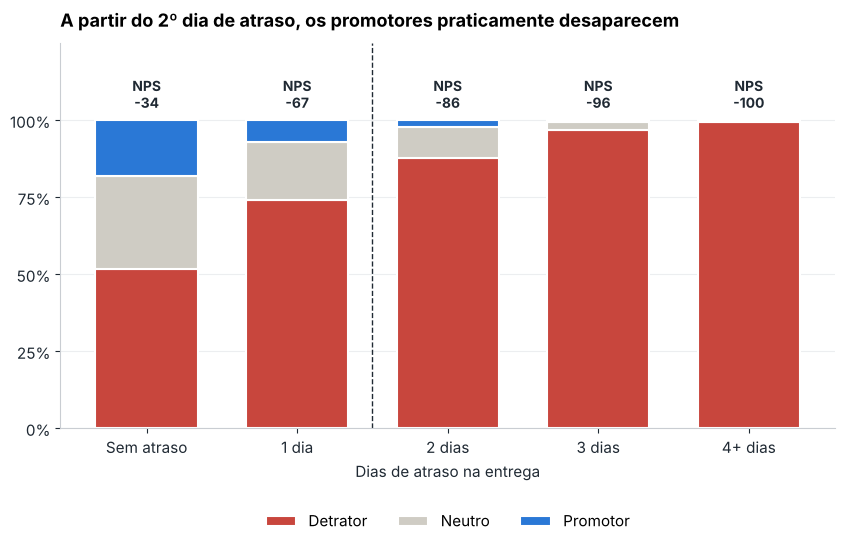

,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_atraso,,,,,
Sem atraso,277,6.9,51.6,18.1,-33.6
1 dia,615,5.5,74.0,7.2,-66.8
2 dias,646,4.6,87.9,2.0,-85.9
3 dias,525,3.4,96.8,0.6,-96.2
4+ dias,437,2.0,99.5,0.0,-99.5


In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
barras_100_por_categoria(ax, composicao_por("faixa_atraso"),
                         "A partir do 2º dia de atraso, os promotores praticamente desaparecem", "Dias de atraso na entrega")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.axvline(1.5, color=COR_TEXTO, linestyle="--", linewidth=1)
salvar_figura(fig, "fig03_ruptura_atraso.png")
plt.show()

resumo_nps_por(df, "faixa_atraso")

In [6]:
# Quanto a nota média cai a cada dia a mais de atraso?
queda_por_dia = df.groupby("delivery_delay_days")["nps_score"].mean()
print(queda_por_dia.round(2).to_string())
print(f"\nQueda média por dia de atraso (0 a 5 dias): {(queda_por_dia[0] - queda_por_dia[5]) / 5:.2f} ponto(s) na nota")

delivery_delay_days
0   6.9
1   5.5
2   4.6
3   3.4
4   2.4
5   1.5
6   1.1
7   0.3
8   0.0

Queda média por dia de atraso (0 a 5 dias): 1.08 ponto(s) na nota

**Leitura para gestão:**
- Cada dia de atraso **tira cerca de 1 ponto** da nota do cliente, de forma constante.
- **Entrega no prazo** é o único cenário com uma parcela relevante de promotores (18%), e mesmo assim o NPS fica em −34.
- Com **1 dia de atraso**, os detratores já são 74%.
- **O ponto de ruptura é o 2º dia de atraso.** Daí em diante os promotores praticamente somem (2% ou menos) e quase 9 em cada 10 clientes viram detratores. Com 4 dias ou mais, a perda é total.
- **64% dos pedidos** chegam com 2 dias ou mais de atraso, ou seja, a maior parte da operação está do lado errado da ruptura.

## 4. Não é a demora, é a promessa quebrada

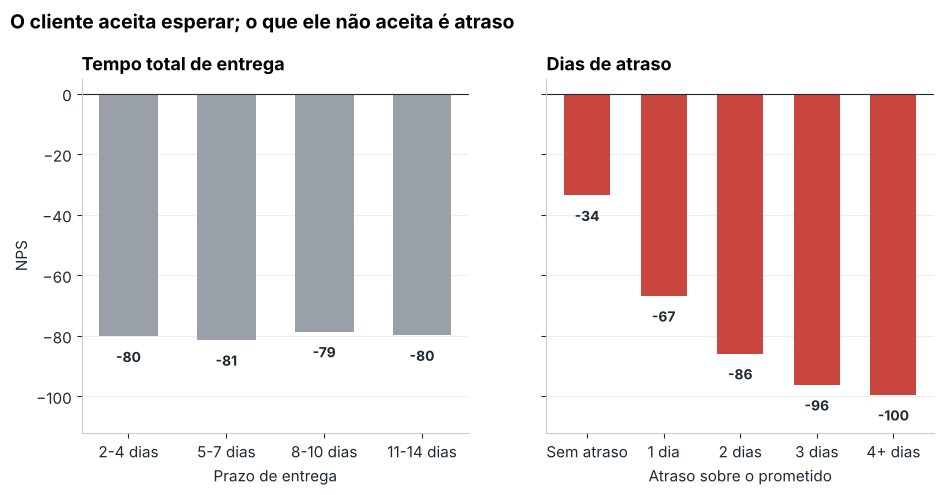

In [7]:
faixa_prazo = pd.cut(df["delivery_time_days"], bins=[1, 4, 7, 10, 14],
                     labels=["2-4 dias", "5-7 dias", "8-10 dias", "11-14 dias"])
nps_por_prazo = df.groupby(faixa_prazo, observed=True)["nps_categoria"].apply(calcular_nps)
nps_por_atraso = df.groupby("faixa_atraso", observed=True)["nps_categoria"].apply(calcular_nps)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, serie, titulo, cor, rotulo in [
    (eixos[0], nps_por_prazo, "Tempo total de entrega", COR_NEUTRA, "Prazo de entrega"),
    (eixos[1], nps_por_atraso, "Dias de atraso", COR_DESTAQUE, "Atraso sobre o prometido"),
]:
    barras = ax.bar(serie.index.astype(str), serie.values, color=cor, width=0.6)
    for barra, valor in zip(barras, serie.values):
        ax.text(barra.get_x() + barra.get_width() / 2, valor - 4, f"{valor:.0f}", ha="center",
                va="top", fontsize=10, fontweight="bold", color=COR_TEXTO)
    ax.axhline(0, color=COR_TEXTO, linewidth=0.8)
    ax.set_title(titulo)
    ax.set_xlabel(rotulo)
eixos[0].set_ylabel("NPS")
eixos[0].set_ylim(-112, 5)
fig.suptitle("O cliente aceita esperar; o que ele não aceita é atraso", x=0.06, ha="left",
             fontsize=14, fontweight="bold", y=1.03)
salvar_figura(fig, "fig04_prazo_vs_atraso.png")
plt.show()

**Leitura para gestão:** um pedido que leva **2 dias** e outro que leva **14 dias** têm praticamente **o mesmo NPS** (em torno de −80). O que derruba a satisfação é **chegar depois do prometido**.

**Implicação prática:** prometer um prazo realista, mesmo que mais longo, é mais eficaz do que prometer rápido e atrasar. Isso abre espaço para revisar a regra de cálculo do prazo exibido no checkout.

## 5. O fator nº 2: atendimento e reclamações

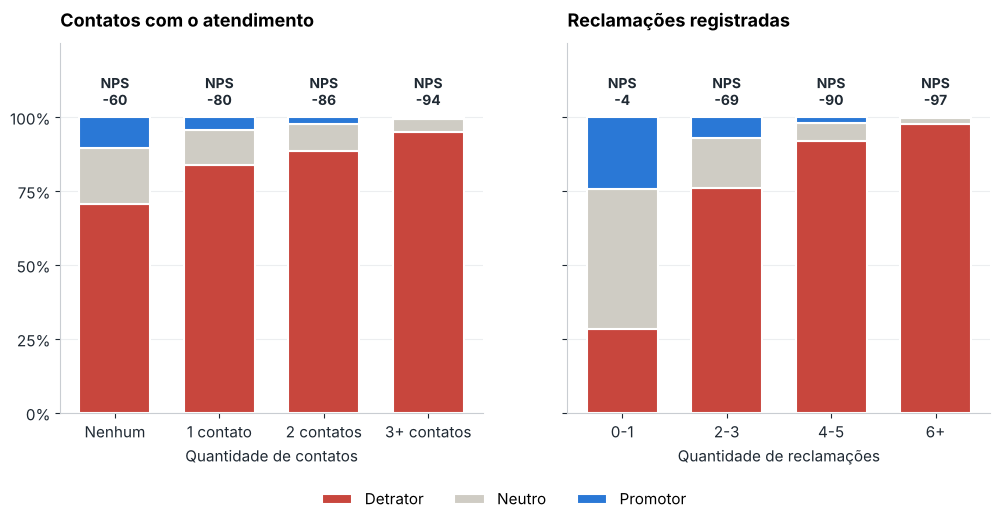

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
barras_100_por_categoria(eixos[0], composicao_por("faixa_contatos"), "Contatos com o atendimento", "Quantidade de contatos")
barras_100_por_categoria(eixos[1], composicao_por("faixa_reclamacoes"), "Reclamações registradas", "Quantidade de reclamações")
eixos[0].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(1.05, -0.17))
salvar_figura(fig, "fig05_atendimento_reclamacoes.png")
plt.show()

In [9]:
resumo_nps_por(df, "faixa_contatos")

,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_contatos,,,,,
Nenhum,554,5.5,70.8,10.3,-60.5
1 contato,816,4.7,83.9,4.4,-79.5
2 contatos,640,4.1,88.6,2.2,-86.4
3+ contatos,490,2.9,94.9,0.6,-94.3


In [10]:
resumo_nps_por(df, "faixa_reclamacoes")

,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_reclamacoes,,,,,
0-1,145,7.9,28.3,24.1,-4.1
2-3,784,5.3,75.9,6.9,-69.0
4-5,1044,4.0,91.9,1.9,-89.9
6+,527,2.8,97.5,0.2,-97.3


**Leitura para gestão:**
- **Cada contato com o atendimento é sinal de que algo deu errado.** Clientes que nunca precisaram ligar têm NPS −60; com 3 contatos ou mais, o NPS cai para −94.
- **Reclamações** são o termômetro mais sensível. Com 0 a 1 reclamação o NPS fica perto de zero (−4), o melhor resultado entre todos os grupos de um único fator. **A partir de 2 reclamações a satisfação desaba** (−69), e com 4 ou mais os detratores passam de 90%.
- Contatos e reclamações andam juntos: quem liga mais, reclama mais.

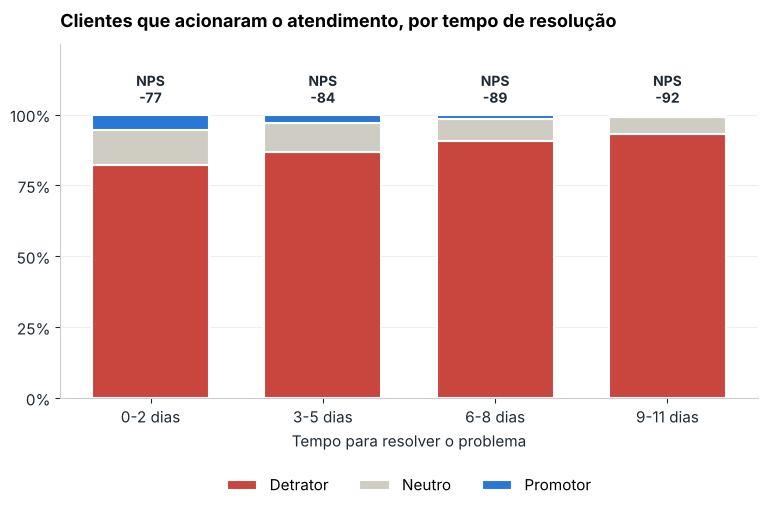

,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_resolucao,,,,,
0-2 dias,499,4.8,82.4,5.4,-77.0
3-5 dias,480,4.2,86.9,3.1,-83.8
6-8 dias,475,3.9,90.5,1.5,-89.1
9-11 dias,492,3.4,93.3,0.8,-92.5


In [11]:
# Tempo de resolução: considerado apenas para quem acionou o atendimento (ver notebook 01)
com_contato = df[df["teve_contato_atendimento"] == 1]
fig, ax = plt.subplots(figsize=(9, 4.6))
barras_100_por_categoria(ax, (pd.crosstab(com_contato["faixa_resolucao"], com_contato["nps_categoria"], normalize="index")
                              .reindex(columns=ORDEM_CATEGORIAS, fill_value=0) * 100),
                         "Clientes que acionaram o atendimento, por tempo de resolução", "Tempo para resolver o problema")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
salvar_figura(fig, "fig06_tempo_resolucao.png")
plt.show()
resumo_nps_por(com_contato, "faixa_resolucao")

**Leitura para gestão:** entre quem acionou o atendimento, resolver em **até 2 dias** mantém 82% de detratores. Passar de **9 dias** eleva esse número para 93%. A velocidade de resolução importa, mas pesa **menos** do que evitar que o problema aconteça. O tempo de resolução não "salva" um pedido que já atrasou.

## 6. O efeito combinado: atraso + atendimento

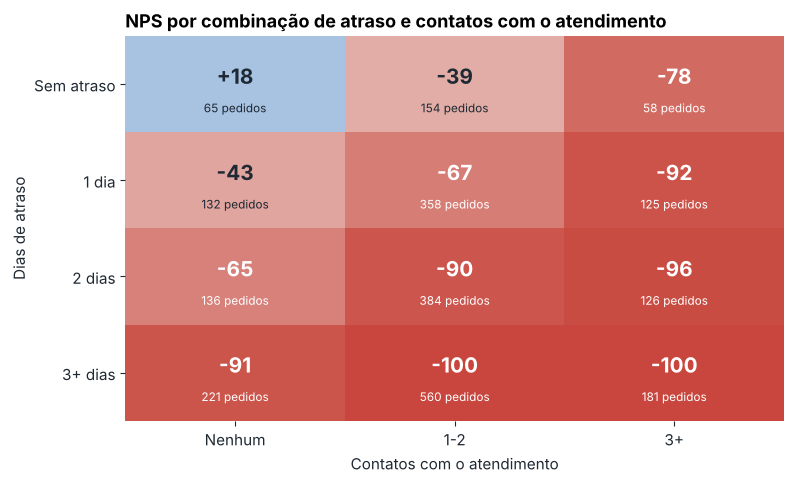

In [12]:
faixa_atraso_curta = pd.cut(df["delivery_delay_days"], [-1, 0, 1, 2, 99], labels=["Sem atraso", "1 dia", "2 dias", "3+ dias"])
faixa_contato_curta = pd.cut(df["customer_service_contacts"], [-1, 0, 2, 99], labels=["Nenhum", "1-2", "3+"])
matriz_nps = df.groupby([faixa_atraso_curta, faixa_contato_curta], observed=True)["nps_categoria"].apply(calcular_nps).unstack()
matriz_qtd = df.groupby([faixa_atraso_curta, faixa_contato_curta], observed=True).size().unstack()

fig, ax = plt.subplots(figsize=(8.5, 5))
# Escala divergente: vermelho = NPS negativo, cinza = 0, azul = positivo
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
mapa = LinearSegmentedColormap.from_list("nps", [COR_DESTAQUE, "#F3EFEA", CORES_CATEGORIA["Promotor"]])
imagem = ax.imshow(matriz_nps.values, cmap=mapa, norm=TwoSlopeNorm(vmin=-100, vcenter=0, vmax=50), aspect="auto")
for i in range(matriz_nps.shape[0]):
    for j in range(matriz_nps.shape[1]):
        valor = matriz_nps.values[i, j]
        cor_texto = "white" if valor < -60 else COR_TEXTO
        ax.text(j, i - 0.08, f"{valor:+.0f}", ha="center", va="center", fontsize=15, fontweight="bold", color=cor_texto)
        ax.text(j, i + 0.25, f"{matriz_qtd.values[i, j]} pedidos", ha="center", va="center", fontsize=8.5, color=cor_texto)
ax.set_xticks(range(matriz_nps.shape[1]), matriz_nps.columns)
ax.set_yticks(range(matriz_nps.shape[0]), matriz_nps.index)
ax.set_xlabel("Contatos com o atendimento")
ax.set_ylabel("Dias de atraso")
ax.grid(False)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("NPS por combinação de atraso e contatos com o atendimento")
salvar_figura(fig, "fig07_matriz_atraso_contato.png")
plt.show()

**Leitura para gestão:** o **único grupo com NPS positivo (+18)** é o de clientes que receberam **no prazo e não precisaram falar com o atendimento**, a experiência "sem atrito". Ele representa só **2,6% dos pedidos** (65 de 2.500). Cada problema a mais empurra o cliente para a zona vermelha, e com **atraso de 3+ dias e 3+ contatos** o NPS é −100: nenhum cliente fica satisfeito.

## 7. Que tipo de cliente tem NPS mais alto ou mais baixo?

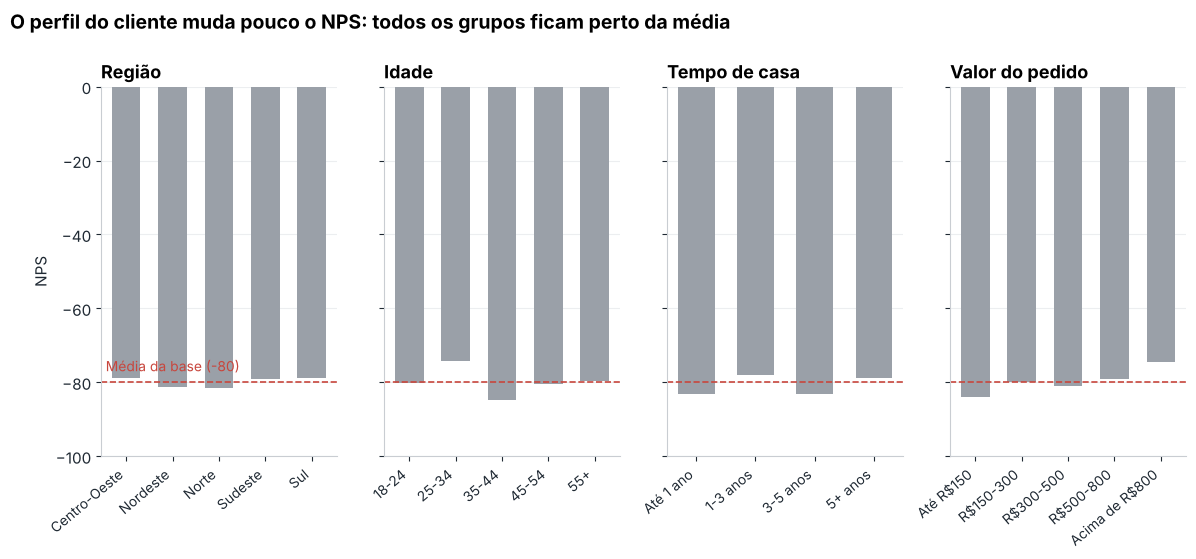

In [13]:
perfis = {
    "Região": "customer_region",
    "Idade": "faixa_idade",
    "Tempo de casa": "faixa_tempo_casa",
    "Valor do pedido": "faixa_valor_pedido",
}
fig, eixos = plt.subplots(1, 4, figsize=(14, 4.8), sharey=True)
for ax, (titulo, coluna) in zip(eixos, perfis.items()):
    serie = df.groupby(coluna, observed=True)["nps_categoria"].apply(calcular_nps)
    ax.bar(serie.index.astype(str), serie.values, color=COR_NEUTRA, width=0.62)
    ax.axhline(nps_geral, color=COR_DESTAQUE, linestyle="--", linewidth=1.2)
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=40, labelsize=10)
    for rotulo in ax.get_xticklabels():
        rotulo.set_horizontalalignment("right")
eixos[0].set_ylabel("NPS")
eixos[0].set_ylim(-100, 0)
eixos[0].text(0.02, nps_geral + 3, f"Média da base ({nps_geral:+.0f})", transform=eixos[0].get_yaxis_transform(),
              color=COR_DESTAQUE, fontsize=10)
fig.suptitle("O perfil do cliente muda pouco o NPS: todos os grupos ficam perto da média",
             x=0.06, ha="left", fontsize=14, fontweight="bold", y=1.04)
salvar_figura(fig, "fig08_perfil_cliente.png")
plt.show()

In [14]:
# Variação do NPS entre o melhor e o pior grupo de cada característica do cliente e do pedido
caracteristicas = {
    "Região": "customer_region", "Idade": "faixa_idade", "Tempo de casa": "faixa_tempo_casa",
    "Valor do pedido": "faixa_valor_pedido",
    "Parcelas": pd.cut(df["payment_installments"], [0, 3, 6, 9, 12]),
    "% de desconto": pd.cut(df["pct_desconto"], [-1, 3, 7, 12, 1000]),
    "Valor do frete": pd.cut(df["freight_value"], [0, 30, 40, 50, 100]),
    "Itens no pedido": "items_quantity",
    "Tentativas de entrega": "delivery_attempts",
}
linhas = []
for nome, agrupador in caracteristicas.items():
    chave = df[agrupador] if isinstance(agrupador, str) else agrupador
    nps_grupos = df.groupby(chave, observed=True)["nps_categoria"].apply(calcular_nps)
    linhas.append({"caracteristica": nome, "pior_nps": nps_grupos.min(), "melhor_nps": nps_grupos.max(),
                   "variacao_em_pontos": nps_grupos.max() - nps_grupos.min()})
pd.DataFrame(linhas).sort_values("variacao_em_pontos")

,caracteristica,pior_nps,melhor_nps,variacao_em_pontos
7,Itens no pedido,-80.7,-79.0,1.7
5,% de desconto,-80.9,-78.3,2.6
0,Região,-81.6,-78.8,2.8
4,Parcelas,-81.6,-78.4,3.2
6,Valor do frete,-82.8,-78.0,4.8
2,Tempo de casa,-83.3,-78.0,5.3
8,Tentativas de entrega,-83.5,-76.1,7.4
3,Valor do pedido,-83.9,-74.5,9.4
1,Idade,-84.9,-74.2,10.7


**Leitura para gestão:**
- **Região, idade, tempo de casa, parcelamento, desconto, frete, quantidade de itens e tentativas de entrega** mudam o NPS em no máximo ~11 pontos, uma diferença pequena perto dos ~66 pontos de variação causados pelo atraso (de −34 para −100).
- Os grupos um pouco melhores (**25 a 34 anos** e pedidos **acima de R$800**, NPS ≈ −75) e o pior (**35 a 44 anos**, −85) estão todos próximos da média.
- **Conclusão:** o NPS não depende de *quem* é o cliente, e sim do *que acontece* com o pedido dele. Isso é uma boa notícia, porque a operação controla esses fatores.
- Curiosidade: o número de **tentativas de entrega** não pesou no NPS. Para o cliente, o que conta é a data em que o pedido chega, não quantas vezes o entregador passou.

## 8. O que mais gera detratores?

Para ordenar os fatores de forma justa, usamos duas leituras complementares, **sem as variáveis que vazam o resultado** (`csat_internal_score` e `repeat_purchase_30d`):

1. **Peso de cada fator:** quanto a qualidade de uma estimativa da nota piora quando "embaralhamos" aquele fator (técnica *permutation importance*, sobre uma floresta aleatória). Quanto maior a piora, mais o fator importa.
2. **Custo de cada unidade:** quanto a nota média cai a cada dia de atraso, contato, reclamação ou dia de resolução a mais, **mantendo os outros fatores iguais** (regressão linear).

> Isso **não é** o modelo preditivo do desafio opcional. É só uma ferramenta para ordenar os fatores da análise exploratória.

Qualidade da estimativa no teste (R²): 0.54

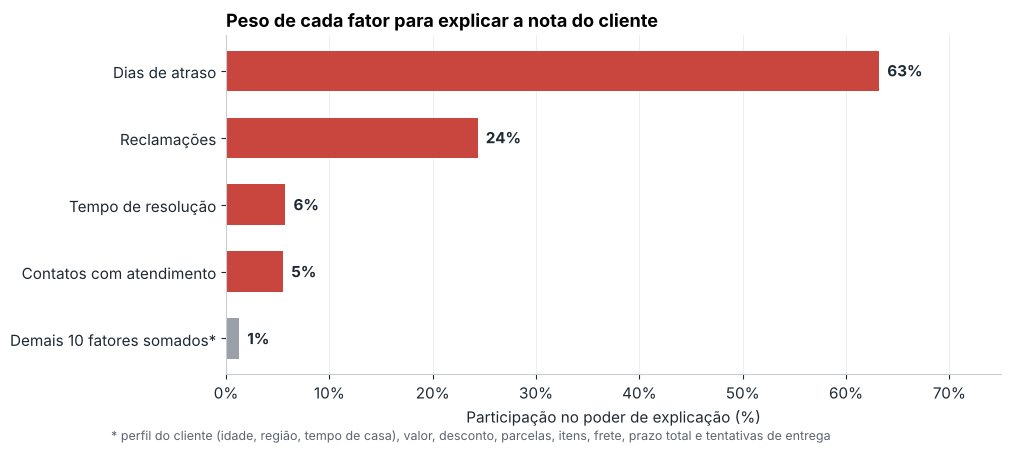

,peso_%
Dias de atraso,63.2
Reclamações,24.3
Tempo de resolução,5.7
Contatos com atendimento,5.5
Valor do pedido,0.9
Idade,0.1
% de desconto,0.1
Tempo de casa,0.1
Região,0.0
Itens no pedido,0.0


In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

nomes_fatores = {
    "delivery_delay_days": "Dias de atraso",
    "complaints_count": "Reclamações",
    "customer_service_contacts": "Contatos com atendimento",
    "resolution_time_days": "Tempo de resolução",
    "delivery_time_days": "Prazo total de entrega",
    "delivery_attempts": "Tentativas de entrega",
    "freight_value": "Valor do frete",
    "order_value": "Valor do pedido",
    "pct_desconto": "% de desconto",
    "payment_installments": "Parcelas",
    "items_quantity": "Itens no pedido",
    "customer_age": "Idade",
    "customer_tenure_months": "Tempo de casa",
}
X = pd.get_dummies(df[list(nomes_fatores) + ["customer_region"]], columns=["customer_region"], drop_first=True).astype(float)
y = df["nps_score"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=42)

floresta = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_treino, y_treino)
resultado = permutation_importance(floresta, X_teste, y_teste, n_repeats=10, random_state=42, n_jobs=-1)
importancia = pd.Series(resultado.importances_mean, index=X.columns)

# Junta as dummies de região em um único fator "Região"
importancia_regiao = importancia.filter(like="customer_region").sum()
importancia = importancia.drop(importancia.filter(like="customer_region").index).rename(nomes_fatores)
importancia["Região"] = importancia_regiao
importancia_pct = (importancia.clip(lower=0) / importancia.clip(lower=0).sum() * 100).sort_values()

# Para o gráfico: os 4 fatores principais + os demais somados (evita uma lista de "0%")
principais = importancia_pct.sort_values(ascending=False).head(4)
demais = importancia_pct.drop(principais.index)
grafico = pd.concat([pd.Series({f"Demais {len(demais)} fatores somados*": demais.sum()}), principais.sort_values()])

fig, ax = plt.subplots(figsize=(10, 4.4))
cores = [COR_NEUTRA] + [COR_DESTAQUE] * len(principais)
ax.barh(grafico.index, grafico.values, color=cores, height=0.6)
for i, valor in enumerate(grafico.values):
    ax.text(valor + 0.8, i, f"{valor:.0f}%", va="center", fontsize=11, fontweight="bold", color=COR_TEXTO)
ax.set_xlim(0, 75)
fig.text(0.01, -0.04, "* perfil do cliente (idade, região, tempo de casa), valor, desconto, parcelas, itens, frete, "
         "prazo total e tentativas de entrega", fontsize=9, color=COR_TEXTO_SECUNDARIO)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Peso de cada fator para explicar a nota do cliente")
ax.set_xlabel("Participação no poder de explicação (%)")
salvar_figura(fig, "fig09_peso_dos_fatores.png")
plt.show()

print(f"Qualidade da estimativa no teste (R²): {floresta.score(X_teste, y_teste):.2f}")
importancia_pct.sort_values(ascending=False).round(1).to_frame("peso_%")

In [16]:
# Custo de cada unidade a mais, mantendo os demais fatores constantes
regressao = LinearRegression().fit(X, y)
efeitos = pd.Series(regressao.coef_, index=X.columns)
custo_unitario = pd.DataFrame({
    "fator": ["1 dia de atraso", "1 reclamação", "1 contato com o atendimento", "1 dia de resolução"],
    "variacao_na_nota": [efeitos["delivery_delay_days"], efeitos["complaints_count"],
                         efeitos["customer_service_contacts"], efeitos["resolution_time_days"]],
})
print(f"Os fatores explicam {regressao.score(X, y):.0%} da variação das notas (R² da regressão linear).")
custo_unitario.round(2)

Os fatores explicam 56% da variação das notas (R² da regressão linear).

,fator,variacao_na_nota
0,1 dia de atraso,-1.0
1,1 reclamação,-0.4
2,1 contato com o atendimento,-0.3
3,1 dia de resolução,-0.1


In [17]:
# De onde vêm os detratores?
detratores = df[df["is_detrator"] == 1]
origem = pd.Series({
    "Tiveram 2+ dias de atraso": (detratores["delivery_delay_days"] >= 2).mean() * 100,
    "Acionaram o atendimento ao menos 1 vez": (detratores["customer_service_contacts"] >= 1).mean() * 100,
    "Tiveram 4+ reclamações": (detratores["complaints_count"] >= 4).mean() * 100,
    "Tiveram atraso OU contato com o atendimento": ((detratores["delivery_delay_days"] >= 1) |
                                                    (detratores["customer_service_contacts"] >= 1)).mean() * 100,
})
origem.round(1).to_frame("% dos detratores")

,% dos detratores
Tiveram 2+ dias de atraso,71.6
Acionaram o atendimento ao menos 1 vez,81.4
Tiveram 4+ reclamações,69.8
Tiveram atraso OU contato com o atendimento,99.3


**Leitura para gestão, o que mais gera detratores:**

| Posição | Fator | Peso | Custo na nota |
|---|---|---|---|
| 1º | **Atraso na entrega** | ≈ 63% | **−1,0 ponto por dia** |
| 2º | **Reclamações** | ≈ 24% | −0,4 por reclamação |
| 3º | **Tempo de resolução** | ≈ 6% | −0,1 por dia |
| 4º | **Contatos com o atendimento** | ≈ 5% | −0,3 por contato |
| — | Perfil do cliente, preço, frete, desconto, parcelas, prazo total | ≈ 1% somados | ≈ 0 |

- Juntos, **atraso e atendimento respondem por ~99% do que explica a nota**.
- **99% dos detratores** passaram por pelo menos um atraso **ou** um contato com o atendimento. Praticamente nenhum detrator surge "do nada".
- **72% dos detratores** tiveram 2 dias ou mais de atraso.
- Os fatores operacionais explicam pouco mais da metade da variação das notas. O restante vem de fatores que a base não registra, como qualidade do produto, expectativa ou embalagem.

## 9. Quanto vale atacar o atraso? (simulação ilustrativa)

Para dar ordem de grandeza às recomendações, simulamos dois cenários de forma **simples e transparente**:

- **Método A (empírico):** os pedidos com 2+ dias de atraso passam a ter a mesma composição de detratores, neutros e promotores observada hoje nos pedidos com 1 dia de atraso.
- **Método B (regressão):** a nota de cada cliente sobe ≈ 1 ponto para cada dia de atraso evitado (coeficiente da seção 8), mantendo todo o resto igual.

> É uma estimativa de potencial, não uma promessa: supõe que o efeito do atraso é causal e que os demais fatores não mudam.

In [18]:
coef_atraso = -efeitos["delivery_delay_days"]  # ≈ 0,96 ponto por dia


def nps_simulado_regressao(atraso_maximo: int) -> float:
    """Recalcula o NPS supondo que nenhum pedido passe de `atraso_maximo` dias de atraso."""
    dias_evitados = df["delivery_delay_days"] - np.minimum(df["delivery_delay_days"], atraso_maximo)
    nota_simulada = (df["nps_score"] + coef_atraso * dias_evitados).clip(0, 10)
    return calcular_nps(nota_simulada.apply(lambda n: "Promotor" if n >= 9 else ("Neutro" if n >= 7 else "Detrator")))


# Método A: pedidos com 2+ dias herdam a composição dos pedidos com 1 dia
mix_1_dia = df.loc[df["delivery_delay_days"] == 1, "nps_categoria"].value_counts(normalize=True)
qtd_2_mais = (df["delivery_delay_days"] >= 2).sum()
mix_simulado = df.loc[df["delivery_delay_days"] < 2, "nps_categoria"].value_counts() + mix_1_dia * qtd_2_mais
nps_metodo_a = round((mix_simulado["Promotor"] - mix_simulado["Detrator"]) / len(df) * 100, 1)

pd.DataFrame({
    "cenario": ["Hoje", "Nenhum pedido passa de 1 dia de atraso", "Nenhum pedido passa de 1 dia de atraso",
                "Atraso zero em todos os pedidos"],
    "metodo": ["Observado", "A (empírico)", "B (regressão)", "B (regressão)"],
    "nps": [nps_geral, nps_metodo_a, nps_simulado_regressao(1), nps_simulado_regressao(0)],
})

,cenario,metodo,nps
0,Hoje,Observado,-80.0
1,Nenhum pedido passa de 1 dia de atraso,A (empírico),-63.1
2,Nenhum pedido passa de 1 dia de atraso,B (regressão),-68.4
3,Atraso zero em todos os pedidos,B (regressão),-48.8


**Leitura para gestão:** só impedir que os pedidos passem do **1º dia de atraso** levaria o NPS de −80 para algo entre **−68 e −63** (+12 a +17 pontos). Zerar o atraso levaria a cerca de **−49** (+31 pontos). O NPS segue negativo, porque atendimento e reclamações também pesam, mas o atraso é a alavanca individual com maior retorno.

## 10. Conclusões da análise exploratória

1. **Atraso é o maior destruidor de satisfação.** Cada dia custa ~1 ponto na nota, e o **2º dia de atraso é o ponto de ruptura**: a partir dele, os promotores somem.
2. **Promessa vale mais que velocidade.** Prazo longo e cumprido gera o mesmo NPS que prazo curto e cumprido. Atraso não é perdoado.
3. **Cada contato com o atendimento é um sintoma.** Reclamações e contatos são o 2º bloco de fatores, e a partir de 2 reclamações a satisfação desaba.
4. **Experiência sem atrito é a única que gera NPS positivo** (+18), mas acontece em só 2,6% dos pedidos.
5. **O perfil do cliente quase não importa.** O problema é operacional e, portanto, gerenciável.
6. **Os sinais aparecem antes da pesquisa.** Atraso, contatos e reclamações são conhecidos *durante* a jornada, e é isso que torna possível agir antes de o cliente dar a nota.

**Limitações:** escala de nota decimal fora do padrão NPS; possíveis inconsistências de definição (reclamações > contatos, tempo de resolução sem contato); ausência de datas e de histórico por cliente; possível base simulada (relação perfeita entre recompra e NPS); análise de **associação**, não de causa e efeito comprovada.